# [IAPR][iapr]: Final project - Chocolate Recognition


**Moodle group ID:** *xx*  
**Kaggle challenge:** *xx* (either `Classic` or `Deep learning`)  
**Kaggle team name (exact):** "*xx*"  

**Author 1 (SCIPER):** *Student Name 1 (xxxxx)*  
**Author 2 (SCIPER):** *Student Name 2 (xxxxx)*  
**Author 3 (SCIPER):** *Student Name 3 (xxxxx)*  

**Due date:** 21.05.2025 (11:59 pm)


## Key Submission Guidelines:
- **Before submitting your notebook, <span style="color:red;">rerun</span> it from scratch!** Go to: `Kernel` > `Restart & Run All`
- **Only groups of three will be accepted**, except in exceptional circumstances.


[iapr]: https://github.com/LTS5/iapr2025

---

> Your comments  
> ...

### Imports :

In [1]:
import os
import sys 
assert (sys.version_info.major == 3) and (sys.version_info.minor == 9)

In [2]:
# if not done yet, install the required packages :
#!pip install -r requirements.txt

In [3]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import mean_absolute_error, r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

import cv2 as cv
import numpy as np

from skimage.feature import local_binary_pattern
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage.util import img_as_ubyte

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from skimage.morphology import remove_small_objects, closing, opening, square, erosion, dilation, disk



In [4]:
# I HOPE WE ARE ALLOWED TO USE THIS PACKAGE !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!pip install torchsummary
from torchsummary import summary

### Paths :

In [5]:
csv_path_background_train = "dataset_project_iapr2025/train/background.csv"
df_background_train = pd.read_csv(csv_path_background_train)

# Dossier des images
img_train_dir = "dataset_project_iapr2025/train/"
img_train_files = sorted([f for f in os.listdir(img_train_dir) if f.lower().endswith(".jpg")])


csv_path_background_test = "dataset_project_iapr2025/test/background.csv"
df_background_test = pd.read_csv(csv_path_background_test)


# Dossier des images
img_test_dir = "dataset_project_iapr2025/test/"
img_test_files = sorted([f for f in os.listdir(img_test_dir) if f.lower().endswith(".jpg")])


### Classify backgrounds with Logistic Regression

#### Do not need to run this cell (1 hour)

In [ ]:
for filename in img_train_files:
    print(f"Traitement de : {filename}")
    path = os.path.join(img_train_dir, filename)

    try:
        image_id = int(filename[1:filename.index('.')])
    except ValueError:
        print(f"⚠️ Nom de fichier invalide : {filename}")
        continue

    if image_id not in df_background_train['id'].values:
        print(f"⚠️ ID {image_id} non présent dans le CSV, ignoré.")
        continue

    img = cv.imread(path)
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

    r_mean, g_mean, b_mean = np.mean(img_rgb, axis=(0, 1))
    gray_mean = np.mean(img_gray)
    gray_std = np.std(img_gray)
    img_edges_std = np.std(cv.Canny(img_gray, 50, 200))

    # Nouvelles features
    s_mean = np.mean(img_hsv[:, :, 1])
    s_std = np.std(img_hsv[:, :, 1])
    v_mean = np.mean(img_hsv[:, :, 2])
    v_std = np.std(img_hsv[:, :, 2])
    lap_var = cv.Laplacian(img_gray, cv.CV_64F).var()

    dark_ratio = np.sum(img_gray < 50) / img_gray.size
    bright_ratio = np.sum(img_gray > 200) / img_gray.size

    # Encore des nouvelles features
    radius = 3
    n_points = 8 * radius
    lbp = local_binary_pattern(img_gray, n_points, radius, method="uniform")
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    lbp_hist = lbp_hist.astype(float) / lbp_hist.sum()  # Normaliser
    lbp_0 = lbp_hist[0]  # LBP 0
    lbp_1 = lbp_hist[1]  # LBP 1
    lbp_2 = lbp_hist[2]  # LBP 2
    lbp_3 = lbp_hist[3]  # LBP 3

    edges = cv.Canny(img_gray, 50, 200)
    edge_ratio = np.sum(edges > 0) / edges.size

    entropy_map = entropy(img_as_ubyte(img_gray), disk(5))
    entropy_mean = np.mean(entropy_map)
    entropy_std = np.std(entropy_map)

    # Mise à jour du CSV
    row_index = df_background_train.index[df_background_train['id'] == image_id][0]
    df_background_train.at[row_index, 'mean_red'] = round(r_mean, 2)
    df_background_train.at[row_index, 'mean_green'] = round(g_mean, 2)
    df_background_train.at[row_index, 'mean_blue'] = round(b_mean, 2)
    df_background_train.at[row_index, 'mean_gray'] = round(gray_mean, 2)
    df_background_train.at[row_index, 'std_gray'] = round(gray_std, 2)
    df_background_train.at[row_index, 'std_contours'] = round(img_edges_std, 2)

    df_background_train.at[row_index, 's_mean'] = round(s_mean, 2)
    df_background_train.at[row_index, 's_std'] = round(s_std, 2)
    df_background_train.at[row_index, 'v_mean'] = round(v_mean, 2)
    df_background_train.at[row_index, 'v_std'] = round(v_std, 2)
    df_background_train.at[row_index, 'lap_var'] = round(lap_var, 2)
    df_background_train.at[row_index, 'dark_ratio'] = round(dark_ratio, 4)
    df_background_train.at[row_index, 'bright_ratio'] = round(bright_ratio, 4)

    df_background_train.at[row_index, 'lbp_0'] = round(lbp_0, 4)
    df_background_train.at[row_index, 'lbp_1'] = round(lbp_1, 4)
    df_background_train.at[row_index, 'lbp_2'] = round(lbp_2, 4)
    df_background_train.at[row_index, 'lbp_3'] = round(lbp_3, 4)
    df_background_train.at[row_index, 'edge_ratio'] = round(edge_ratio, 4)
    df_background_train.at[row_index, 'entropy_mean'] = round(entropy_mean, 4)
    df_background_train.at[row_index, 'entropy_std'] = round(entropy_std, 4)

# Enregistrement du CSV mis à jour
df_background_train.to_csv(csv_path_background_train, index=False)
print("✅ CSV mis à jour avec les nouvelles features.")


Traitement de : L1000756.JPG


In [6]:
# Définir toutes les features utilisées
feature_cols = [
    'mean_red', 'mean_green', 'mean_blue',
    'mean_gray', 'std_gray', 'std_contours',
    's_mean', 's_std', 'v_mean', 'v_std',
    'lap_var', 'dark_ratio', 'bright_ratio',
    'lbp_0', 'lbp_1', 'lbp_2', 'lbp_3',
    'edge_ratio', 'entropy_mean', 'entropy_std'
]

# X : features, y : labels
X = df_background_train[feature_cols]
y = df_background_train['background'].astype(int)

# Pipeline : standardisation + régression logistique multinomiale
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs', max_iter=1000, random_state=0)
)

# Entraîner le modèle
model.fit(X, y)

# Prédictions sur le même set (train)
y_pred = model.predict(X)

# Évaluation des performances
print("📊 Rapport de classification (régression logistique) :\n")
print(classification_report(y, y_pred, digits=3, target_names=[
    "Blank", "Book", "Board", "Flowers", "Bag", "Plastic"
]))

print("📉 Matrice de confusion :")
print(confusion_matrix(y, y_pred))

print(f"✅ Accuracy sur les données d'entraînement : {accuracy_score(y, y_pred)*100:.2f}%")


📊 Rapport de classification (régression logistique) :

              precision    recall  f1-score   support

       Blank      1.000     1.000     1.000        30
        Book      1.000     1.000     1.000        10
       Board      1.000     1.000     1.000        10
     Flowers      1.000     1.000     1.000        20
         Bag      1.000     1.000     1.000        10
     Plastic      1.000     1.000     1.000        10

    accuracy                          1.000        90
   macro avg      1.000     1.000     1.000        90
weighted avg      1.000     1.000     1.000        90

📉 Matrice de confusion :
[[30  0  0  0  0  0]
 [ 0 10  0  0  0  0]
 [ 0  0 10  0  0  0]
 [ 0  0  0 20  0  0]
 [ 0  0  0  0 10  0]
 [ 0  0  0  0  0 10]]
✅ Accuracy sur les données d'entraînement : 100.00%


#### Check logistic regression with all features on test set :

#### Do not need to run this cell (2 hours)

In [ ]:
for filename in img_test_files:
    print(f"Traitement de : {filename}")
    path = os.path.join(img_test_dir, filename)

    try:
        image_id = int(filename[1:filename.index('.')])
    except ValueError:
        print(f"⚠️ Nom de fichier invalide : {filename}")
        continue

    if image_id not in df_background_test['id'].values:
        print(f"⚠️ ID {image_id} non présent dans le CSV, ignoré.")
        continue

    img = cv.imread(path)
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

    r_mean, g_mean, b_mean = np.mean(img_rgb, axis=(0, 1))
    gray_mean = np.mean(img_gray)
    gray_std = np.std(img_gray)
    img_edges_std = np.std(cv.Canny(img_gray, 50, 200))

    # Nouvelles features
    s_mean = np.mean(img_hsv[:, :, 1])
    s_std = np.std(img_hsv[:, :, 1])
    v_mean = np.mean(img_hsv[:, :, 2])
    v_std = np.std(img_hsv[:, :, 2])
    lap_var = cv.Laplacian(img_gray, cv.CV_64F).var()

    dark_ratio = np.sum(img_gray < 50) / img_gray.size
    bright_ratio = np.sum(img_gray > 200) / img_gray.size

    # Encore des nouvelles features
    radius = 3
    n_points = 8 * radius
    lbp = local_binary_pattern(img_gray, n_points, radius, method="uniform")
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    lbp_hist = lbp_hist.astype(float) / lbp_hist.sum()  # Normaliser
    lbp_0 = lbp_hist[0]  # LBP 0
    lbp_1 = lbp_hist[1]  # LBP 1
    lbp_2 = lbp_hist[2]  # LBP 2
    lbp_3 = lbp_hist[3]  # LBP 3

    edges = cv.Canny(img_gray, 50, 200)
    edge_ratio = np.sum(edges > 0) / edges.size

    entropy_map = entropy(img_as_ubyte(img_gray), disk(5))
    entropy_mean = np.mean(entropy_map)
    entropy_std = np.std(entropy_map)

    # Mise à jour du CSV
    row_index = df_background_test.index[df_background_test['id'] == image_id][0]
    df_background_test.at[row_index, 'mean_red'] = round(r_mean, 2)
    df_background_test.at[row_index, 'mean_green'] = round(g_mean, 2)
    df_background_test.at[row_index, 'mean_blue'] = round(b_mean, 2)
    df_background_test.at[row_index, 'mean_gray'] = round(gray_mean, 2)
    df_background_test.at[row_index, 'std_gray'] = round(gray_std, 2)
    df_background_test.at[row_index, 'std_contours'] = round(img_edges_std, 2)

    df_background_test.at[row_index, 's_mean'] = round(s_mean, 2)
    df_background_test.at[row_index, 's_std'] = round(s_std, 2)
    df_background_test.at[row_index, 'v_mean'] = round(v_mean, 2)
    df_background_test.at[row_index, 'v_std'] = round(v_std, 2)
    df_background_test.at[row_index, 'lap_var'] = round(lap_var, 2)
    df_background_test.at[row_index, 'dark_ratio'] = round(dark_ratio, 4)
    df_background_test.at[row_index, 'bright_ratio'] = round(bright_ratio, 4)

    df_background_test.at[row_index, 'lbp_0'] = round(lbp_0, 4)
    df_background_test.at[row_index, 'lbp_1'] = round(lbp_1, 4)
    df_background_test.at[row_index, 'lbp_2'] = round(lbp_2, 4)
    df_background_test.at[row_index, 'lbp_3'] = round(lbp_3, 4)
    df_background_test.at[row_index, 'edge_ratio'] = round(edge_ratio, 4)
    df_background_test.at[row_index, 'entropy_mean'] = round(entropy_mean, 4)
    df_background_test.at[row_index, 'entropy_std'] = round(entropy_std, 4)

# Enregistrement du CSV mis à jour
df_background_test.to_csv(csv_path_background_test, index=False)
print("✅ CSV mis à jour avec les nouvelles features.")


Traitement de : L1000757.JPG
Traitement de : L1000758.JPG
Traitement de : L1000759.JPG
Traitement de : L1000760.JPG
Traitement de : L1000761.JPG
Traitement de : L1000762.JPG
Traitement de : L1000764.JPG
Traitement de : L1000766.JPG
Traitement de : L1000767.JPG
Traitement de : L1000769.JPG
Traitement de : L1000770.JPG
Traitement de : L1000773.JPG
Traitement de : L1000774.JPG
Traitement de : L1000775.JPG
Traitement de : L1000776.JPG
Traitement de : L1000777.JPG
Traitement de : L1000778.JPG
Traitement de : L1000781.JPG
Traitement de : L1000782.JPG
Traitement de : L1000783.JPG
Traitement de : L1000784.JPG
Traitement de : L1000786.JPG
Traitement de : L1000789.JPG
Traitement de : L1000790.JPG
Traitement de : L1000794.JPG
Traitement de : L1000795.JPG
Traitement de : L1000796.JPG
Traitement de : L1000798.JPG
Traitement de : L1000800.JPG
Traitement de : L1000801.JPG
Traitement de : L1000806.JPG
Traitement de : L1000807.JPG
Traitement de : L1000809.JPG
Traitement de : L1000811.JPG
Traitement de 

In [7]:
# === Définir X_test et y_test directement depuis le CSV
X_test = df_background_test[feature_cols]
y_test = df_background_test['background'].astype(int)

# === Prédictions avec ton modèle déjà entraîné
y_pred = model.predict(X_test)

# === Évaluation
print("\n📊 Résultats sur le set de test (features CSV) :")
print(classification_report(y_test, y_pred, digits=3, target_names=[
    "Blank", "Book", "Board", "Flowers", "Bag", "Plastic"
]))

print("📉 Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))

print(f"✅ Accuracy test : {accuracy_score(y_test, y_pred) * 100:.2f}%")



📊 Résultats sur le set de test (features CSV) :
              precision    recall  f1-score   support

       Blank      0.983     1.000     0.991        58
        Book      1.000     1.000     1.000        20
       Board      1.000     1.000     1.000        20
     Flowers      1.000     1.000     1.000        40
         Bag      1.000     1.000     1.000        20
     Plastic      1.000     0.955     0.977        22

    accuracy                          0.994       180
   macro avg      0.997     0.992     0.995       180
weighted avg      0.995     0.994     0.994       180

📉 Matrice de confusion :
[[58  0  0  0  0  0]
 [ 0 20  0  0  0  0]
 [ 0  0 20  0  0  0]
 [ 0  0  0 40  0  0]
 [ 0  0  0  0 20  0]
 [ 1  0  0  0  0 21]]
✅ Accuracy test : 99.44%


#### PERFECT, especially since the only error is on something that can be interpreted as belonging to 2 classes.

### Find the good preprocessing on each background :

#### Blank background :

### Essaye watershed direct à la place de filtrage (https://www.youtube.com/watch?v=3MUxPn3uKSk&t=18s&ab_channel=KevinWood%7CRobotics%26AI) et (https://docs.opencv.org/4.x/d3/db4/tutorial_py_watershed.html):

In [ ]:
from scipy.ndimage import binary_fill_holes
from skimage.feature import peak_local_max
from scipy import ndimage


def remove_objects(binary_mask, min_size):
    return remove_small_objects(binary_mask > 0, min_size=min_size)

def apply_gaussian_several_times(img, kernel_size, sigma, times):
    copy = img.copy()
    for _ in range(times):
        copy = cv.GaussianBlur(copy, (kernel_size, kernel_size), sigma)
    return copy


def detect_contours_single_img_debug(img, size=11):
    img = cv.resize(img, (0, 0), fx=0.25, fy=0.25)  # Réduction à 25% de la taille originale
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    img_copy = img_rgb.copy()

    remove_objects_size = 250 # 200
    thres2 = 2
    sigma = 50 #16 #2.7, 12 bien
    p2 = 32
    th_sigma = 5#2.5
    close_th = 30

    # Atténuation des canaux rouge et vert
    img_att = img_rgb.copy()
    img_att[:, :, 0] = img_att[:, :, 0] * 1  # red
    img_att[:, :, 1] = img_att[:, :, 1] * 1  # green
    img_att[:, :, 2] = img_att[:, :, 2] * 1  # blue

    img_hsv = cv.cvtColor(img_att, cv.COLOR_RGB2HSV)
    img_hsv[:, :, 0] = img_hsv[:, :, 0] * 1  # Atténuation de la teinte
    img_hsv[:, :, 1] = img_hsv[:, :, 1] * 0.5 # Atténuation de la saturation
    img_hsv[:, :, 2] = img_hsv[:, :, 2] * 1  # Atténuation de la valeur (luminosité)
    img_att = cv.cvtColor(img_hsv, cv.COLOR_HSV2RGB)


    # Inversion + passage en niveaux de gris
    imgGray = cv.cvtColor(255 - img_att, cv.COLOR_RGB2GRAY)

    low_pass = apply_gaussian_several_times(imgGray, size, sigma, 10)
    high_pass = cv.subtract(imgGray, low_pass)
    _, thresholded = cv.threshold(high_pass, thres2, 255, cv.THRESH_BINARY)
    thresholded = np.uint8(remove_objects(thresholded, remove_objects_size)) * 255
    thresholded_opening = cv.morphologyEx(thresholded, cv.MORPH_OPEN, cv.getStructuringElement(cv.MORPH_RECT, (2,2)))
    thresholded_closing = cv.morphologyEx(thresholded_opening, cv.MORPH_CLOSE, cv.getStructuringElement(cv.MORPH_RECT, (close_th, close_th)))
    thresholded_blur = cv.GaussianBlur(thresholded_closing, (size, size), th_sigma)

    filled_image = binary_fill_holes(thresholded_blur > 0)  # Résultat booléen
    filled_image = filled_image.astype(np.uint8) * 255     # Convertir en image binaire = image de base pour la détection de contours
    filled_image = cv.morphologyEx(filled_image, cv.MORPH_OPEN, cv.getStructuringElement(cv.MORPH_ELLIPSE, (10,10)))

    sure_background = cv.dilate(filled_image, disk(5), iterations=1)  # Dilatation pour le fond, le noir est du sure background
    # Finding sure foreground area
    dist_transform = cv.distanceTransform(filled_image,cv.DIST_L2,5)
    """
    ret, sure_foreground = cv.threshold(dist_transform, 0.4*dist_transform.max(), 255, 0)
    # Finding unknown region
    sure_foreground = np.uint8(sure_foreground)
    unknown = cv.subtract(sure_background,sure_foreground)

    # Marker labelling
    ret, markers = cv.connectedComponents(sure_foreground)
    
    # Add one to all labels so that sure background is not 0, but 1
    markers = markers+1
    
    # Now, mark the region of unknown with zero
    markers[unknown==255] = 0
    """
    coordinates = peak_local_max(dist_transform, min_distance=20, labels=filled_image)
    
    local_max = np.zeros_like(dist_transform, dtype=bool)
    local_max[tuple(coordinates.T)] = True
    local_max = cv.dilate(local_max.astype(np.uint8), disk(30), iterations=1)  # Dilatation pour élargir les maxima locaux
    sure_foreground, _ = ndimage.label(local_max)

    
    unknown = cv.subtract(sure_background, np.uint8(sure_foreground > 0) * 255)

    # Marqueurs pour Watershed
    markers = sure_foreground + 1
    markers[unknown == 255] = 0
    
    markers = np.int32(markers)

    labels = cv.watershed(img,markers)

    # Marquer les contours avec épaisseur plus grande
    contour_mask = (labels == -1).astype(np.uint8) * 255
    # Dilatation pour épaissir les contours
    kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))  # (5,5) pour plus épais
    contour_mask_dilated = cv.dilate(contour_mask, kernel, iterations=2)
    # Appliquer le masque dilaté à l'image
    img_copy[contour_mask_dilated == 255] = [255, 0, 0]

    return img_att, imgGray, low_pass, high_pass, thresholded, thresholded_opening, thresholded_closing, thresholded_blur, filled_image, sure_background, dist_transform, sure_foreground, unknown, markers, labels, img_copy



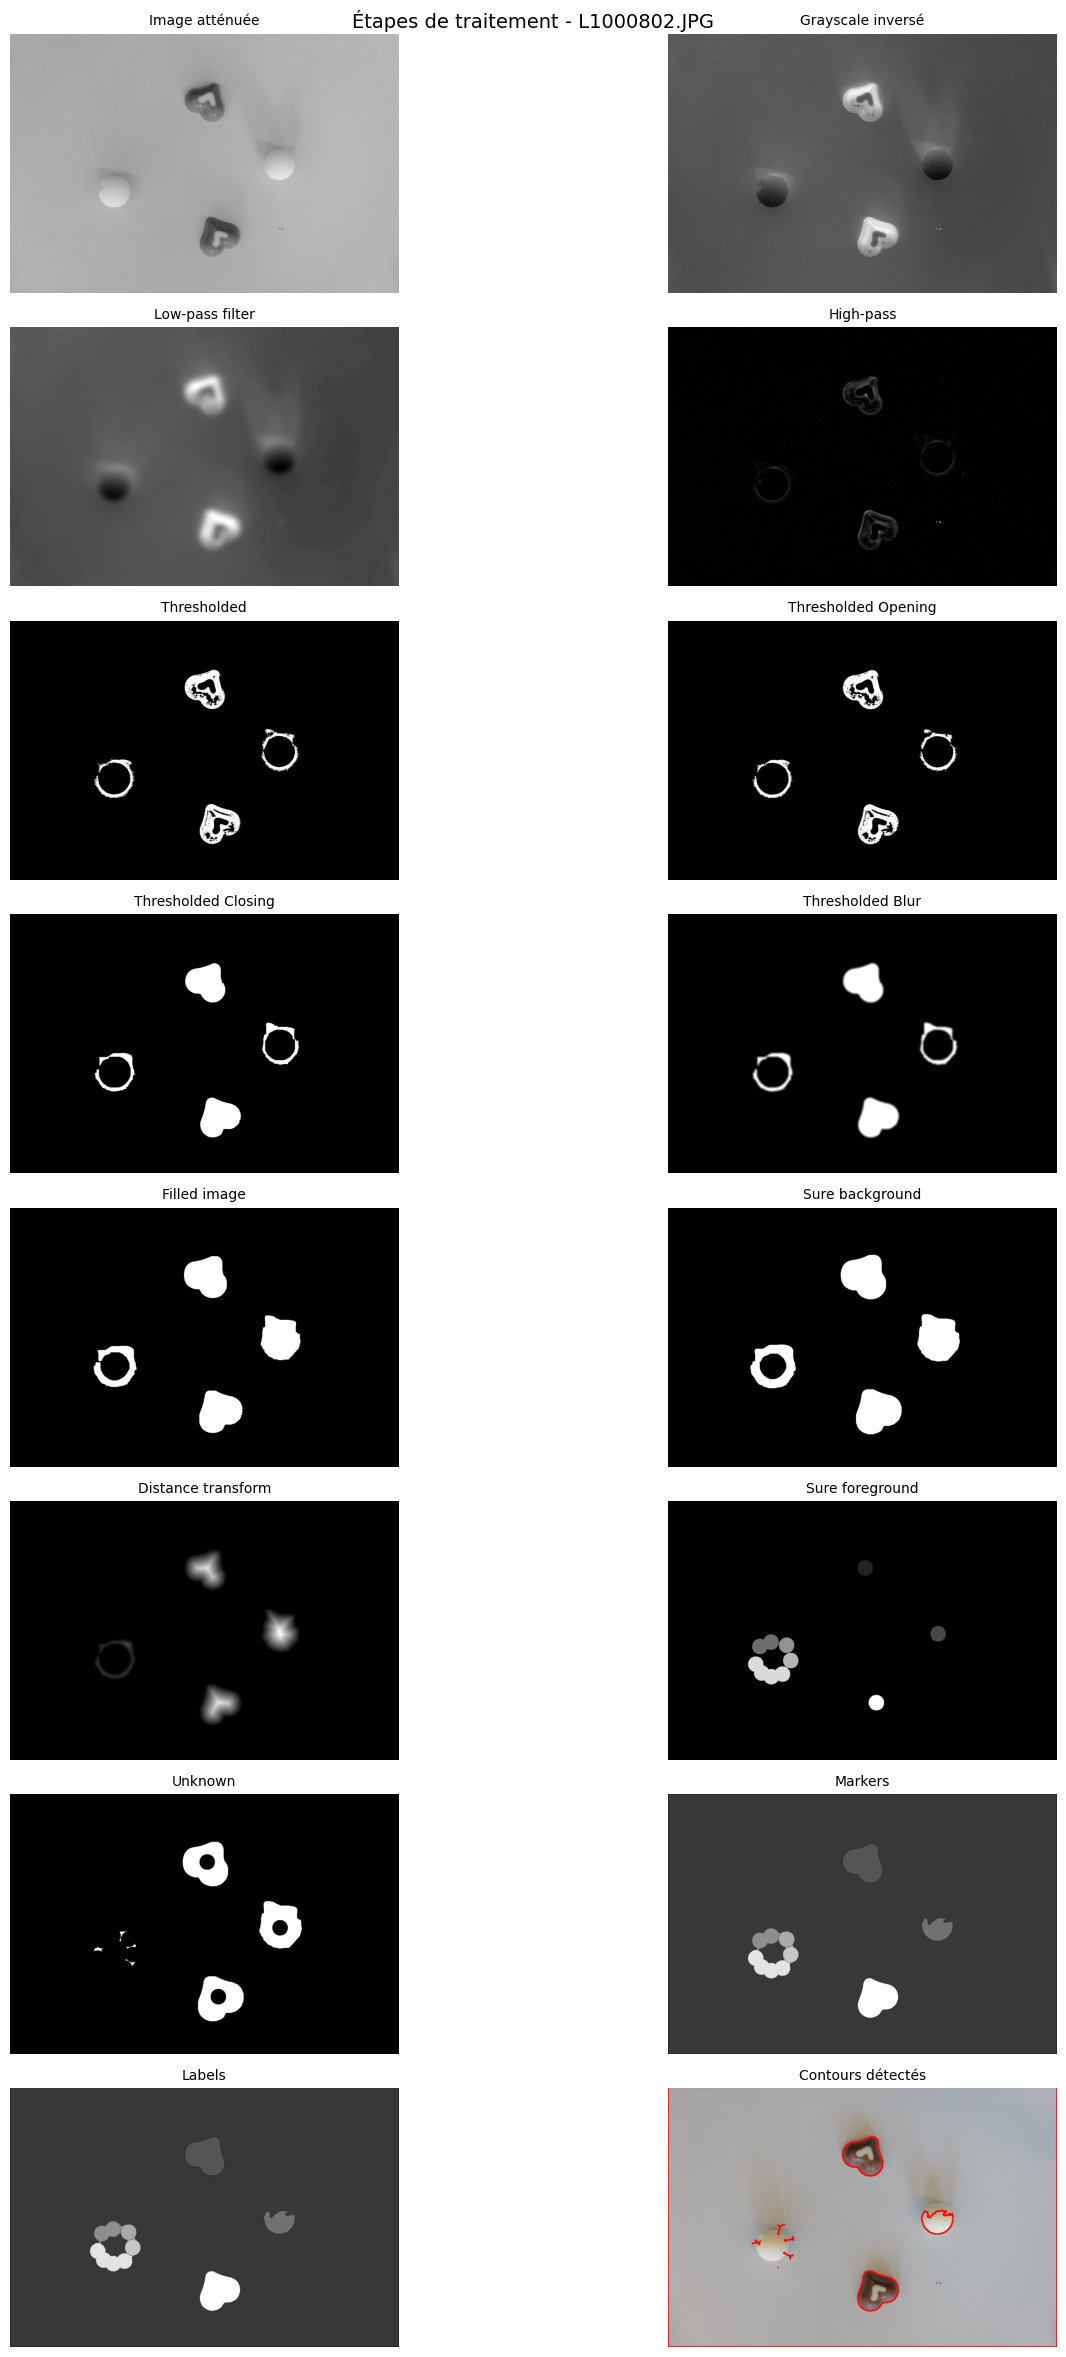

In [139]:
X = df_background_train[feature_cols]
y_pred = model.predict(X)

# === Récupérer les IDs prédits comme background 1 ===
ids_predicted_1 = df_background_train['id'][y_pred == 1].values

for image_id in ids_predicted_1:
    filename = f"L{image_id}.JPG"
    path = os.path.join(img_train_dir, filename)
    if filename != "L1000802.JPG":
        continue


    if not os.path.exists(path):
        print(f"⚠️ Fichier manquant : {filename}")
        continue

    img = cv.imread(path)

    imgs = detect_contours_single_img_debug(img)

    titles = [
    "Image atténuée",
    "Grayscale inversé",
    "Low-pass filter",
    "High-pass",
    "Thresholded",
    "Thresholded Opening",
    "Thresholded Closing",
    "Thresholded Blur",
    "Filled image",
    "Sure background",
    "Distance transform",
    "Sure foreground",
    "Unknown",
    "Markers",
    "Labels",
    "Contours détectés"
    ]
    

    fig, axes = plt.subplots(nrows=8, ncols=2, figsize=(16, 24))  # taille adaptée
    for i, (title, im) in enumerate(zip(titles, imgs)):
        ax = axes[i // 2, i % 2]
        cmap = "gray" if len(im.shape) == 2 else None
        ax.imshow(im, cmap=cmap)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

    plt.suptitle(f"Étapes de traitement - {filename}", fontsize=14)
    plt.tight_layout()
    plt.show()



### Essaye filtres couleurs (bof):

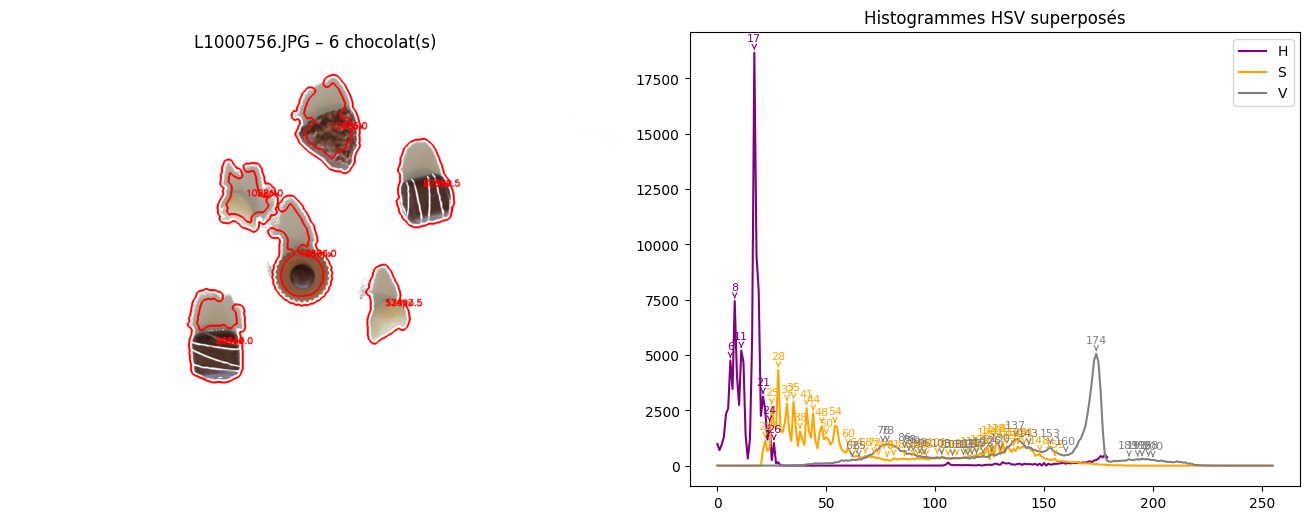

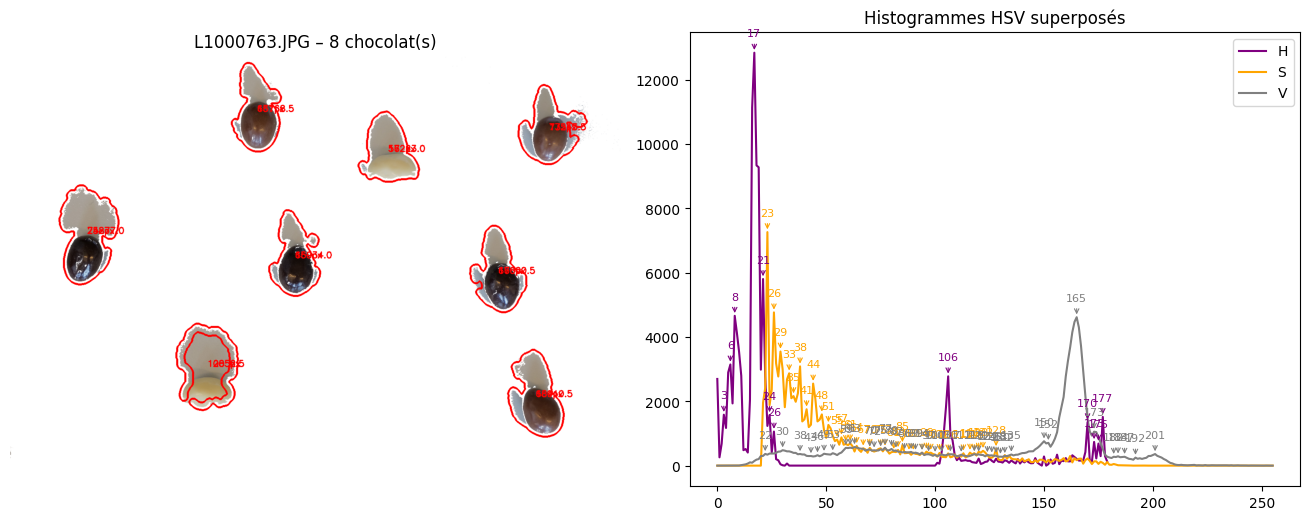

KeyboardInterrupt: 

c:\Users\Utilisateur\OneDrive\Bureau\Cours\EPFL\MA2\IAPR\venv_IAPR\lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


In [ ]:
def detect_chocolates(img, size=45):
    # Prétraitement
    std = np.std(cv.cvtColor(255 - img, cv.COLOR_BGR2GRAY))
    img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Détection des pixels où R, G et B sont tous entre 170 et 190
    mask_rgb = (
        (img[:, :, 0] >= 160) &  (img[:, :, 0] <= 190) &# R
        (img[:, :, 1] >= 160) &  (img[:, :, 1] <= 190) &# G
        (img[:, :, 2] >= 160) &  (img[:, :, 2] <= 190)# B
    )

    # Appliquer la couleur blanche aux pixels correspondants
    img[mask_rgb] = [255, 255, 255]

    img_hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)

    mask_hsv = (
        (img_hsv[:, :, 1] >= 0) &  (img_hsv[:, :, 1] <= 20)
    )
    img[mask_hsv] = [255, 255, 255]


    img = cv.resize(img, (0, 0), fx=0.25, fy=0.25)
    img_copy = img.copy()


    img_edges_std = np.std(cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 50, 200))

    # Paramètres adaptatifs, mais appliqués sans disjonction finale
    remove_objects_size = 120
    thres2 = 3
    sigma = 2.7
    p2 = 38
    th_sigma = 2.7
    open_th = 6

    img[:, :, 0] = img[:, :, 0] * 0.25  # red
    img[:, :, 1] = img[:, :, 1] * 0.25  # green
    img[:, :, 2] = img[:, :, 2] * 1     # blue

    imgGray = cv.cvtColor(255 - img, cv.COLOR_BGR2GRAY)

    low_pass = cv.GaussianBlur(imgGray, (size, size), sigma)
    high_pass = cv.subtract(imgGray, low_pass)
    _, thresholded = cv.threshold(high_pass, thres2, 255, cv.THRESH_BINARY)

    thresholded = np.uint8(remove_objects(thresholded, remove_objects_size) * 255)
    thresholded_closing = apply_closing(thresholded, open_th)
    thresholded_blur = cv.GaussianBlur(thresholded_closing.astype(np.uint8) * 255, (size, size), th_sigma)

    contours, _ = cv.findContours(thresholded_blur, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    chocolates = [cnt for cnt in contours if 2000 < cv.contourArea(cnt) < 50000]
    

    for cnt in chocolates:
        area = cv.contourArea(cnt)
        M = cv.moments(cnt)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = cnt[0][0]
        cv.putText(img_copy, f"{area}", (cx, cy), cv.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)


    
    for cnt in chocolates:
        cv.drawContours(img_copy, [cnt], -1, (255, 0, 0), 3)
        length = int(cv.arcLength(cnt, True))
        M = cv.moments(cnt)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = cnt[0][0]
        cv.putText(img_copy, f"{length}px", (cx, cy), cv.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    
    return img_copy, len(chocolates)

# Traitement de toutes les images dans un dossier
input_dir = "dataset_project_iapr2025/train"
image_files = [f for f in os.listdir(input_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

from scipy.signal import find_peaks

for file in sorted(image_files):
    img_path = os.path.join(input_dir, file)
    img = cv.imread(img_path)
    result_img, count = detect_chocolates(img)

    # Détection des pixels où R, G et B sont tous entre 170 et 190
    mask_rgb = (
        (img[:, :, 0] >= 160) &  (img[:, :, 0] <= 190) &  # R
        (img[:, :, 1] >= 160) &  (img[:, :, 1] <= 190) &  # G
        (img[:, :, 2] >= 160) &  (img[:, :, 2] <= 190)    # B
    )
    img[mask_rgb] = [255, 255, 255]

    img_rgb = cv.cvtColor(cv.resize(img, (0, 0), fx=0.25, fy=0.25), cv.COLOR_BGR2RGB)
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

    mask_hsv = (
        (img_hsv[:, :, 1] >= 0) &  (img_hsv[:, :, 1] <= 20)
    )
    img_rgb[mask_hsv] = [255, 255, 255]
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

    # Masque pour exclure le blanc pur
    mask = ~np.all(img_rgb == [255, 255, 255], axis=-1)
    mask = mask.astype(np.uint8) * 255

    # Histogrammes
    r_hist = cv.calcHist([img_rgb], [0], mask, [256], [0, 256]).flatten()
    g_hist = cv.calcHist([img_rgb], [1], mask, [256], [0, 256]).flatten()
    b_hist = cv.calcHist([img_rgb], [2], mask, [256], [0, 256]).flatten()
    h_hist = cv.calcHist([img_hsv], [0], mask, [180], [0, 180]).flatten()
    s_hist = cv.calcHist([img_hsv], [1], mask, [256], [0, 256]).flatten()
    v_hist = cv.calcHist([img_hsv], [2], mask, [256], [0, 256]).flatten()

    fig = plt.figure(figsize=(20, 10))

    # Image avec détection
    ax1 = fig.add_subplot(2, 3, 1)
    ax1.imshow(result_img)
    ax1.set_title(f"{file} – {count} chocolat(s)")
    ax1.axis('off')

    # Histogrammes HSV
    ax3 = fig.add_subplot(2, 3, 2)
    for hist, color, label in zip([h_hist, s_hist, v_hist], ['purple', 'orange', 'gray'], ['H', 'S', 'V']):
        ax3.plot(hist, color=color, label=label)
        peaks, _ = find_peaks(hist, height=np.max(hist) * 0.05)
        for peak in peaks:
            ax3.annotate(str(peak), xy=(peak, hist[peak]), xytext=(peak, hist[peak] + 500),
                         ha='center', color=color, fontsize=8,
                         arrowprops=dict(arrowstyle='->', color=color, lw=0.8))
    ax3.set_title("Histogrammes HSV superposés")
    ax3.legend()

    plt.tight_layout()
    plt.show()


### Paths :

In [ ]:
dataset_dir = "dataset_project_iapr2025"
images_train_dir = os.path.join(dataset_dir, "train")
images_test_dir = os.path.join(dataset_dir, "test")

train_csv_path = os.path.join(dataset_dir, "train.csv")

In [ ]:
dataframe_train = pd.read_csv(train_csv_path)
dataframe_train["filename"] = dataframe_train["id"].apply(lambda x: f"L{x:07d}.JPG")
print(dataframe_train)

          id  Jelly White  Jelly Milk  Jelly Black  Amandina  Crème brulée  \
0    1000001            1           0            0         0             0   
1    1000002            0           1            0         0             0   
2    1000003            0           0            1         0             0   
3    1000004            0           0            0         1             0   
4    1000005            0           0            0         0             1   
..       ...          ...         ...          ...       ...           ...   
98   1010031            0           0            0         0             0   
99   1010032            0           0            0         0             0   
100  1010035            0           0            0         0             0   
101  1010041            0           0            0         2             0   
102  1010045            1           1            1         1             1   

     Triangolo  Tentation noir  Comtesse  Noblesse  Noir authen

In [ ]:
def check_image_sizes(image_dir):
    sizes = set()  # set() only keeps unique values
    
    for filename in os.listdir(image_dir):
        if filename.endswith(".JPG"):
            img_path = os.path.join(image_dir, filename)
            image = Image.open(img_path)
            sizes.add(image.size)  # Adds the size (width, height) to the set
    
    if len(sizes) > 1:
        print("Images are of different sizes:")
        print(sizes)
    else:
        print("Every image has the same size :", sizes)

check_image_sizes(images_train_dir)
check_image_sizes(images_test_dir)

Every image has the same size : {(6000, 4000)}
Every image has the same size : {(6000, 4000)}


### Datasets : 2 differents because we have a csv for the training set and we don't for the testing set

In [ ]:
class ChocolateTrainDataset(Dataset): # inherits from Dataset class in PyTorch
    def __init__(self, dataframe, images_dir, transform=None):
        self.dataframe = dataframe # dataframe = raw data
        self.images_dir = images_dir # directory where images are stored
        self.transform = transform # transformations to be applied to images
        self.labels = dataframe.iloc[:, 1:-1].values # all columns except the first and last one (id and filename)
        self.filenames = dataframe["filename"].values

    def __len__(self):
        return len(self.dataframe) # number of samples in the dataset

    def __getitem__(self, idx): # will be called each time we iterate over the dataset in a dataloader
        img_name = os.path.join(self.images_dir, self.filenames[idx])
        image = Image.open(img_name).convert("RGB")
        if self.transform:
            image = self.transform(image) # will be applied each time we iterate over the dataset in a dataloader
        
        label = torch.tensor(self.labels[idx], dtype=torch.float32)  # 13 classes
        return image, label
    
class ChocolateTestDataset(Dataset):
    def __init__(self, images_dir, transform=None):
        self.images_dir = images_dir
        self.transform = transform
        self.image_paths = sorted(glob.glob(os.path.join(images_dir, "*.JPG"))) # does not have a csv/dataframe like the training dataset => need to find the filenames by ourselves

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Create the train dataset and dataloader WITHOUT normalization
train_dataset = ChocolateTrainDataset(dataframe_train, images_train_dir, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)


# Create the test dataset and dataloader WITHOUT normalization
test_dataset = ChocolateTestDataset(images_test_dir, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [ ]:
def calculate_mean_std(dataloader):
    means = []
    stds = []
    for batch in dataloader: # enable to handle train_loader and test_loader
        if isinstance(batch, (list, tuple)): # batch is a tuple (images, labels) for train_loader
            images = batch[0]  # (images, labels)
        else: # batch is a tensor for test_loader
            images = batch  # (images,)
        means.append(torch.mean(images, dim=[0, 2, 3])) # size of the image is (batch_size, channels, height, width) => mean for each channel (RGB), output is (3,)
        stds.append(torch.std(images, dim=[0, 2, 3])) # std for each channel (RGB)
    
    mean = torch.mean(torch.stack(means), dim=0).numpy()
    std = torch.mean(torch.stack(stds), dim=0).numpy()
    return mean, std




# Calculate mean and std with the dataloader
mean_train, std_train = calculate_mean_std(train_loader)

print(f"Mean train: {mean_train}")
print(f"Std train: {std_train}")

# Data augmentation and normalization for training
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)),  # Random translation and zoom
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),  # Gaussian blur with random sigma
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_train, std=std_train) #normalization after data augmentation, with values calculated before augmentation but it is a good approximation
])

# Recreate the train dataset and dataloader WITH its normalization and data augmentation
train_dataset = ChocolateTrainDataset(dataframe_train, images_train_dir, transform=transform_train)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)



# Calculate mean and std with the dataloader
mean_test, std_test = calculate_mean_std(test_loader)

print(f"Mean test: {mean_test}")
print(f"Std test: {std_test}")

# We do NOT apply data augmentation on the test dataset, only normalization
transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_test, std=std_test)
])

# Recreate the test dataset and dataloader WITH its normalization
test_dataset = ChocolateTestDataset(images_test_dir, transform=transform_test)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

Mean train: [0.6888842  0.66838366 0.6627756 ]
Std train: [0.1579174  0.15635023 0.17798379]
Mean test: [0.6871095  0.6585127  0.65092844]
Std test: [0.16302747 0.16433911 0.18869422]


### CNN : MAYBE WE NEED TO USE ATTENTION GATED POOLING LIKE LAB 3 ???????????????????????? 

In [ ]:
class Attn_Net_Gated(nn.Module):
    def __init__(self, L: int, M: int):
        super().__init__()
        self.fc1_V = nn.Linear(L, M)
        self.fc1_U = nn.Linear(L, M)
        self.fc2 = nn.Linear(M, 1)

    def forward(self, x):
        att_tanh = torch.tanh(self.fc1_V(x))      # (N, M)
        att_sigmoid = torch.sigmoid(self.fc1_U(x))# (N, M)
        A = att_tanh * att_sigmoid                # (N, M)
        A = self.fc2(A)                           # (N, 1)
        return A


class AttentionPooling(nn.Module):
    def __init__(self, L: int, M: int):
        super().__init__()
        self.attention_net = Attn_Net_Gated(L, M)

    def forward(self, x, attention_only=False):
        coeffs = self.attention_net(x)     # (N, 1)
        A = F.softmax(coeffs, dim=0).T     # (1, N)
        Y = torch.matmul(A, x)             # (1, L)
        return A if attention_only else Y



class ChocolateCounterCNN(nn.Module):
    def __init__(self, patch_size=4, attn_dim=128):
        super().__init__()
        
        # CNN feature extractor
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  # 3 -> 16
            nn.ReLU(),
            nn.MaxPool2d(2),  # 224 -> 112
            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 -> 32
            nn.ReLU(),
            nn.MaxPool2d(2),  # 112 -> 56
            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 -> 64
            nn.ReLU(),
            nn.MaxPool2d(2),  # 56 -> 28
        )

        self.patch_size = patch_size
        self.embedding_dim = 64 * patch_size * patch_size
        self.attn_pool = AttentionPooling(L=self.embedding_dim, M=attn_dim)

        self.fc_layers = nn.Sequential(
            nn.Linear(self.embedding_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 13),    # 13 types de chocolats
            nn.ReLU()              # on veut des valeurs >= 0
        )

    def forward(self, x):
        features = self.conv_layers(x)  # (B, C, H, W)
        B, C, H, W = features.shape

        # Découpe en patchs via unfold
        patches = F.unfold(features, kernel_size=self.patch_size, stride=self.patch_size)  # (B, C*P*P, N)
        patches = patches.transpose(1, 2)  # (B, N, C*P*P)

        # Appliquer attention pooling à chaque image du batch
        pooled = torch.stack([self.attn_pool(patch) for patch in patches])  # (B, 1, C*P*P)
        pooled = pooled.squeeze(1)  # (B, C*P*P)

        output = self.fc_layers(pooled)  # (B, 13)
        return output
    
    @staticmethod # defines that the following function does not take self as input
    @torch.no_grad() # ensures that following function runs without tracking gradients
    # making the initialisation faster and more memory-efficient. The parameters remain trainable.
    def init_weights(module):
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.constant_(module.weight, 1)
            nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, mode='fan_in', nonlinearity='relu')
            nn.init.constant_(module.bias, 0)
        """
        elif isinstance(module, nn.Linear):
            init.xavier_uniform_(m.weight)
            if m.bias is not None:
                init.constant_(m.bias, 0)
        
        """
        return
"""
class ChocolateCounterCNN(nn.Module):
    def __init__(self):
        super(ChocolateCounterCNN, self).__init__() # call the constructor of the parent class nn.Module
        
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), # 3 channels (RGB) -> 16 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 224x224 pixels to 112x112

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 channels -> 32 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 112x112 pixels to 56x56

            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 channels -> 64 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 56x56 pixels to 28x28

            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 64 channels -> 128 channels
            nn.ReLU(),
            nn.MaxPool2d(2), # from 28x28 pixels to 14x14
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(), # flatten the output of the conv layers
            nn.Linear(128 * 14*14, 512), # 128 channels * (14*14) pixels to 512 neurons
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 13),  # 13 types of chocolates
            nn.ReLU() # don't want negative values for the output
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

"""
    
    

"\nclass ChocolateCounterCNN(nn.Module):\n    def __init__(self):\n        super(ChocolateCounterCNN, self).__init__() # call the constructor of the parent class nn.Module\n        \n        self.conv_layers = nn.Sequential(\n            nn.Conv2d(3, 16, kernel_size=3, padding=1), # 3 channels (RGB) -> 16 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2),  # from 224x224 pixels to 112x112\n\n            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 channels -> 32 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2),  # from 112x112 pixels to 56x56\n\n            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 channels -> 64 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2),  # from 56x56 pixels to 28x28\n\n            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 64 channels -> 128 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2), # from 28x28 pixels to 14x14\n        )\n\n        self.fc_layers = nn.Sequential(\n            nn.Flat

In [ ]:
actual_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ChocolateCounterCNN().to(actual_device)  # <- modèle sur GPU
model.apply(ChocolateCounterCNN.init_weights) # applies initialisation, goes through every layers

summary(model, (3, 224, 224), device = actual_device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 224, 224]             448
              ReLU-2         [-1, 16, 224, 224]               0
         MaxPool2d-3         [-1, 16, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]           4,640
              ReLU-5         [-1, 32, 112, 112]               0
         MaxPool2d-6           [-1, 32, 56, 56]               0
            Conv2d-7           [-1, 64, 56, 56]          18,496
              ReLU-8           [-1, 64, 56, 56]               0
         MaxPool2d-9           [-1, 64, 28, 28]               0
           Linear-10                  [-1, 128]         131,200
           Linear-11                  [-1, 128]         131,200
           Linear-12                    [-1, 1]             129
   Attn_Net_Gated-13                    [-1, 1]               0
 AttentionPooling-14                 [-

## From practise 3 DL :

In [ ]:
def mae(preds, target):
    return mean_absolute_error(target, preds)

def r2(preds, target):
    return r2_score(target, preds)


def train_epoch(model, optimizer, criterion, metrics, train_loader, device):
    
    # we activate the training state for the model
    model.train()

    # initialize epoch loss and metrics
    epoch_loss = 0
    epoch_metrics = dict(zip(metrics.keys(), torch.zeros(len(metrics))))

    # we iterate over the batches
    for batch_num, (x_batch, y_batch) in tqdm(enumerate(train_loader)):
        data = x_batch.to(device) # (batch_size, channels, height, width)
        target = y_batch.to(device) #Le terme device dans PyTorch fait référence à l'appareil (CPU ou GPU) sur lequel les tenseurs et les modèles sont stockés et exécutés.

        # Clean previously computed gradients
        optimizer.zero_grad()
        
        # Forward pass
        output = model(data) #calcule les prédictions du modèle. (scores bruts, pas encore les argmax)

        # Compute loss
        loss = criterion(output, target)

        # Compute gradients and optimize the model parameters
        loss.backward() #calcule les gradients
        optimizer.step() #met à jour les paramètres du modèle.
        
        '''
        Compute predictions and metrics
        Store predictions in variable preds
        No gradients should be propagated at this step
        '''
        with torch.no_grad(): #Cela garantit que PyTorch n'enregistre pas les opérations associées à torch.max() dans le graphe computationnel, ce qui évite une consommation mémoire excessive et optimise l'entraînement.
            preds = output.detach().cpu()
            target = target.detach().cpu()
            for k in epoch_metrics.keys():
                epoch_metrics[k] += metrics[k](preds, target)


        # log loss statistics
        epoch_loss += loss.item()

    # for the epoch loss, we take the average of the losses computed over the mini-batches
    epoch_loss /= len(train_loader)

    # for the epoch loss, we compute the average of the metrics over the mini-batches
    for k in epoch_metrics.keys():
          epoch_metrics[k] /= len(train_loader)

    clear_output() #clean the prints from previous epochs
    print('train Loss: {:.4f}, '.format(epoch_loss),
          ', '.join(['{}: {:.4f}'.format(k, epoch_metrics[k]) for k in epoch_metrics.keys()]))

    return epoch_loss,  epoch_metrics


In [ ]:
def plot_training(train_loss, metrics_names, train_metrics_logs):
    fig, ax = plt.subplots(1, len(metrics_names) + 1, figsize=((len(metrics_names) + 1) * 5, 5))

    ax[0].plot(train_loss, c='blue', label='train')
    ax[0].set_title('Loss')
    ax[0].set_xlabel('epoch')
    ax[0].legend()

    for i in range(len(metrics_names)):
        ax[i + 1].plot(train_metrics_logs[i], c='blue', label='train')
        ax[i + 1].set_title(metrics_names[i])
        ax[i + 1].set_xlabel('epoch')
        ax[i + 1].legend()

    plt.show()

def update_metrics_log(metrics_names, metrics_log, new_metrics_dict):
    '''
    - metrics_names: the keys/names of the logged metrics
    - metrics_log: existing metrics log that will be updated
    - new_metrics_dict: epoch_metrics output from train_epoch and evaluate functions
    '''
    for i in range(len(metrics_names)):
        curr_metric_name = metrics_names[i]
        metrics_log[i].append(new_metrics_dict[curr_metric_name])
    return metrics_log

In [ ]:
def train_cycle(model, optimizer, criterion, metrics, train_loader, n_epochs, device):
    train_loss_log = []
    metrics_names = list(metrics.keys())
    train_metrics_log = [[] for _ in range(len(metrics))]

    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1} / {n_epochs}")
        train_loss, train_metrics = train_epoch(model, optimizer, criterion, metrics, train_loader, device)

        train_loss_log.append(train_loss)
        train_metrics_log = update_metrics_log(metrics_names, train_metrics_log, train_metrics)

        plot_training(train_loss_log, metrics_names, train_metrics_log)

    return train_metrics_log


train Loss: 0.5952,  MAE: 0.5895, R²: -0.0551


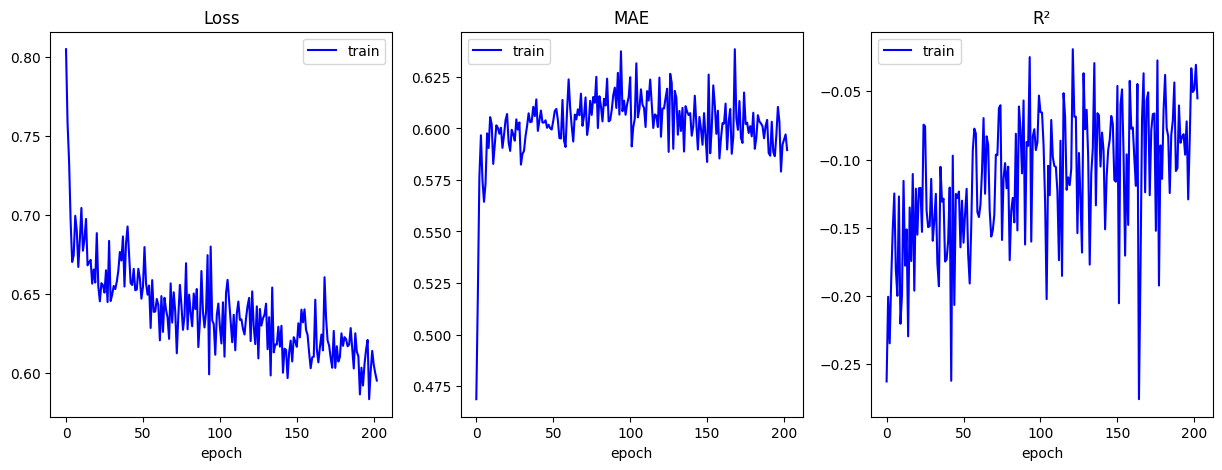

Epoch 204 / 500


0it [00:00, ?it/s]


KeyboardInterrupt: 

In [ ]:
torch.manual_seed(42)

model = ChocolateCounterCNN()

metrics = {'MAE': mae, 'R²': r2}


#optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4) # or lr=1e-3

criterion = nn.MSELoss()  # or nn.L1Loss() if we want to be more robust to outliers or criterion = torch.nn.SmoothL1Loss()

N_EPOCHS = 500
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}")

model.to(device)
criterion.to(device)

train_metrics_log = train_cycle(model, optimizer, criterion, metrics, train_loader=train_loader, n_epochs=N_EPOCHS, device=device)

# save model weights
results_models_weights_dir = 'models_weights/'
if not os.path.exists(results_models_weights_dir):
    os.mkdir(results_models_weights_dir)
torch.save(model.state_dict(), results_models_weights_dir + 'base_model.pth')

### Create predictions csv :

In [ ]:
# List of chocolate names (13 classes), the order is the same as in the dataframe
chocolate_names = [
    "Jelly White", "Jelly Milk", "Jelly Black",
    "Amandina", "Crème brulée", "Triangolo",
    "Tentation noir", "Comtesse", "Noblesse",
    "Noir authentique", "Passion au lait", "Arabia",
    "Stracciatella"
]

def generate_predictions_csv(model, test_loader, device, output_path="submission.csv"):
    model.eval()
    predictions = []
    image_ids = []

    with torch.no_grad():
        for batch_idx, x_batch in tqdm(enumerate(test_loader)):

            x_batch = x_batch.to(device)
            outputs = model(x_batch)
            outputs = torch.round(outputs).cpu().numpy().astype(int)

            # Find the image IDs from the filenames and store them in a list with the predictions
            batch_size = outputs.shape[0]
            for i in range(batch_size):
                # Example : extract "1000756" from ".../1000756.jpg"
                path = test_loader.dataset.image_paths[batch_idx * test_loader.batch_size + i]
                image_id_str = os.path.splitext(os.path.basename(path))[0]  # 'L1000757' for example
                image_id = int(re.sub(r'\D', '', image_id_str))  # Remove non-digit characters
                image_ids.append(image_id)
                predictions.append(outputs[i])

    # Creation of the DataFrame
    df = pd.DataFrame(predictions, columns=chocolate_names)
    df.insert(0, "id", image_ids)
    df.to_csv(output_path, index=False)
    print(f" CSV uploaded : {output_path}")


In [ ]:
# Assure-toi que le modèle est en mode évaluation et chargé sur le bon appareil
model.to(actual_device)

# Appelle la fonction
generate_predictions_csv(model, test_loader, actual_device)

0it [00:07, ?it/s]

batch_size 15
path dataset_project_iapr2025\test\L1000757.JPG


NameError: name 're' is not defined